## Task 1: Setting the Baseline

In ML, it is essential to establish a baseline model for comparison with any developments.

### Task 1.1 Data Preparation and Validation Pipeline

- First, explore the training data for any anomalies and visualize some trajectories. Each trajectory consists of 258 lines, one per data point. Note that after a collision, all lines of that trajectory will be zero up to the 258th data point for that trajectory.

Necessary imports

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Load dataset from CSV file and analyze it in terms of missing values and dataset summary

In [32]:
df = pd.read_csv('../mlNOVA/X_train.csv')
df.drop(columns=['v_x_1','v_y_1','v_x_2','v_y_2','v_x_3','v_y_3'], inplace=True) # Velocities don't seem to help

print(df.isnull().sum())
print(df.describe())
df.head()

                  t           x_1           y_1           x_2           y_2  \
count  1.285000e+06  1.285000e+06  1.285000e+06  1.285000e+06  1.285000e+06   
mean   4.145262e+00 -2.812879e-01 -1.095159e-01  7.171403e-03 -8.201144e-02   
std    3.209813e+00  1.695764e+00  1.167686e+00  1.062984e+00  1.038606e+00   
min    0.000000e+00 -3.082300e+01 -1.785773e+01 -3.083340e+01 -5.245081e+01   
25%    1.054690e+00 -4.118489e-01 -3.928434e-01 -3.295574e-01 -1.918623e-01   
50%    3.945310e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
75%    6.953120e+00  5.008268e-01  2.634242e-01  2.103091e-01  2.683916e-01   
max    1.000000e+01  1.634061e+01  2.627623e+01  1.550696e+01  3.567946e+01   

                x_3           y_3            Id  
count  1.285000e+06  1.285000e+06  1.285000e+06  
mean   2.741165e-01  1.915273e-01  6.424995e+05  
std    1.443411e+00  1.683294e+00  3.709477e+05  
min   -1.743999e+01 -3.316000e+01  0.000000e+00  
25%   -4.324075e-01 -4.472183e-01  3.2

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


Dataframe should have the data grouped by scenarios

In [ ]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe or https://www.statology.org/pandas-chunk-dataframe/
SUBFRAME_SIZE = 257

def fixed_size_subframes(data, n):
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]

Visualize trajectories

1110


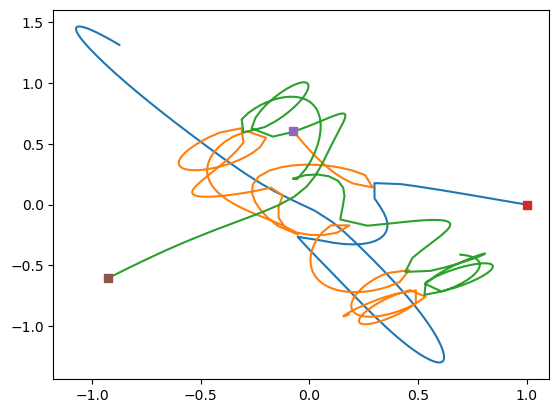

In [33]:
subframes = fixed_size_subframes(df, SUBFRAME_SIZE)

k = np.random.randint(len(subframes))
print(k)

subframe = subframes[k]
first_row = subframe.iloc[0]

plt.plot(subframe.x_1, subframe.y_1)
plt.plot(subframe.x_2, subframe.y_2)
plt.plot(subframe.x_3, subframe.y_3)

plt.plot(first_row.x_1, first_row.y_1, 's')
plt.plot(first_row.x_2, first_row.y_2, 's')
plt.plot(first_row.x_3, first_row.y_3, 's')

Create features and target matrices from the grouped data

In [30]:
def create_features_and_targets(subframes):
    X_list = []
    y_list = []
    
    for df in subframes:
        initial_conditions = df.iloc[0][['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']].values
        
        for i, row in df.iterrows():
            features = [row['t']] + initial_conditions.tolist()
            X_list.append(features)
            
            targets = row[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']].values
            y_list.append(targets)

    X = pd.DataFrame(X_list, columns=['t', 'x0_1', 'y0_1', 'x0_2', 'y0_2', 'x0_3', 'y0_3'])
    y = pd.DataFrame(y_list, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])
    
    return X, y


X, y = create_features_and_targets(subframes)

Features and target matrices should have information grouped by scenario

In [54]:
X_chunks = fixed_size_subframes(X, SUBFRAME_SIZE)
y_chunks = fixed_size_subframes(y, SUBFRAME_SIZE)

print(X_chunks[0].head())
print(y_chunks[0].head())

          t  x0_1  y0_1      x0_2      y0_2      x0_3      y0_3
0  0.000000   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
1  0.039062   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
2  0.078125   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
3  0.117188   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
4  0.156250   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
        x_1       y_1       x_2       y_2       x_3       y_3
0  1.000000  0.000000 -0.266467  0.859196 -0.733533 -0.859196
1  0.999548  0.000092 -0.266261  0.858781 -0.733287 -0.858874
2  0.998190  0.000370 -0.265641  0.857535 -0.732549 -0.857905
3  0.995925  0.000833 -0.264606  0.855456 -0.731318 -0.856289
4  0.992747  0.001483 -0.263154  0.852540 -0.729592 -0.854022


Split dataset into training (80%), validation (10%) and test (10%) sets.

In [89]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

print(X_train[0].head())
print(y_train[0].head())

                t  x0_1  y0_1      x0_2      y0_2      x0_3      y0_3
1086339  0.000000   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
1086340  0.039062   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
1086341  0.078125   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
1086342  0.117188   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
1086343  0.156250   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
              x_1       y_1       x_2       y_2       x_3       y_3
1086339  1.000000  0.000000 -0.141885  0.949936 -0.858115 -0.949936
1086340  0.999578  0.000141 -0.141685  0.949542 -0.857894 -0.949683
1086341  0.998312  0.000566 -0.141082  0.948358 -0.857229 -0.948924
1086342  0.996198  0.001275 -0.140077  0.946383 -0.856121 -0.947658
1086343  0.993234  0.002270 -0.138666  0.943612 -0.854568 -0.945883


Concatenate the list of DataFrames into single DataFrames for X and y

In [90]:
X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

Linear regression model

In [105]:
degree=1

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      LinearRegression())

# Fit the model
polyreg.fit(X_train_df, y_train_df)

# Predict the targets for the validation set
y_dev_pred = polyreg.predict(X_dev_df)

Plot the y-y hat and present the RMSE in the validation set

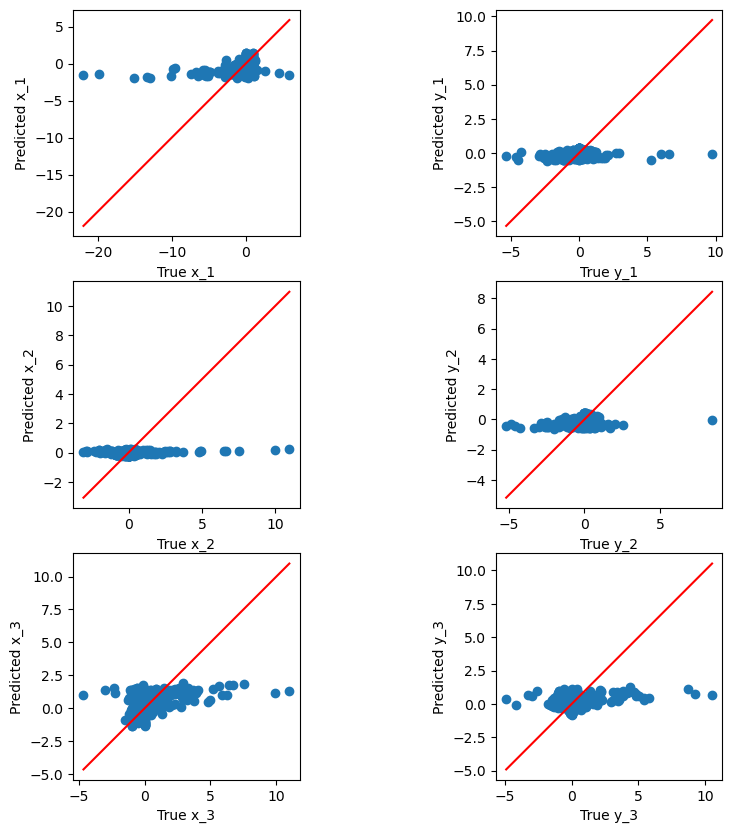

Validation RMSE: 1.3345699794722141


In [106]:
def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()
    
plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_dev_df, y_dev_pred))

# Print RMSE
print(f"Validation RMSE: {rmse}")

RMSE on the test set

In [107]:
# Predict the targets for the validation set
y_test_pred = polyreg.predict(X_test_df)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test_df, y_test_pred))

# Print RMSE
print(f"Test RMSE: {rmse}")

Test RMSE: 1.4425975556989512


Regarding the baseline model for submission of task 1.2

In [112]:
X_baseline_df = pd.read_csv('../mlNOVA/X_test.csv')
X_baseline_df.drop(columns=['Id'], inplace=True)

y_baseline_pred = polyreg.predict(X_baseline_df)

predictions_df = pd.DataFrame(y_baseline_pred, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

predictions_df['Id'] = range(len(y_baseline_pred))

predictions_df = predictions_df[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]

predictions_df.to_csv('../submissions/baseline_model.csv', index=False)